In [95]:
import math
import numpy as np
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import erf
from IPython.display import Markdown

## 1. `date_score()` → date_score, remove

In [96]:
zero_crossing=5
MAX_SCORE = 10

USAGE_WINDOW = 30        # Tage, ueber die die App-Nutzung gezaehlt wird ("ein Monat")
COUNT_USAGE_APP =13 #getUsage(USAGE_WINDOW) Past number of Days App use DURING USAGE_WINDOW
COUNT_RECIPES_COOKED_ATLEAST_TWICE =25 #recipes coooked more equal than twice (Update when you write in that Recipe was counted,Only Up no checking every Recipe everytime)
average_usage = USAGE_WINDOW / COUNT_USAGE_APP            # ~2.31 Tage zwischen Nutzungen
periodcycle_app = average_usage * COUNT_RECIPES_COOKED_ATLEAST_TWICE

tau = 1 * (periodcycle_app - zero_crossing) / np.arctanh(0.8)     # ab welchem Abstand (Tage) Punkte als "nah" gelten

def date_score_curve(amp, dist_last):
    return MAX_SCORE * np.tanh(amp / tau * (np.asarray(dist_last, dtype=float) - zero_crossing))



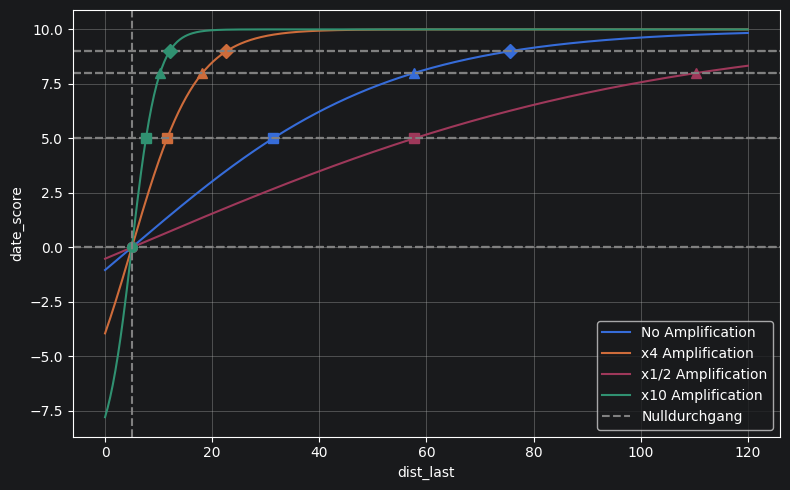

In [97]:
dist_last = np.linspace(0, 120, 500)
amplification={1: "No Amplification", 4: "x4 Amplification", 0.5: "x1/2 Amplification", 10: "x10 Amplification"}
LEVELS = {0: "o", 0.5: "s", 0.8: "^", 0.9: "D"}   # Anteil vom Maximum : Marker

fig, ax = plt.subplots(figsize=(8, 5))
for amp,label in amplification.items():
    line, = ax.plot(dist_last, date_score_curve(amp, dist_last), label=label, )
    c = amp / tau
    for p, m in LEVELS.items():
            ax.axhline(p*MAX_SCORE,color="gray",ls="--")
            x = zero_crossing + np.arctanh(p) / c
            if x <= dist_last.max():
                ax.plot(x, p * MAX_SCORE, m, color=line.get_color(), ms=7)
ax.axvline(zero_crossing,color="gray",ls="--",label="Nulldurchgang")
ax.set_xlabel("dist_last")
ax.set_ylabel("date_score")
plt.tight_layout()
ax.legend()
ax.grid()
plt.show()

### Der Date Score Wird Bestimmt mit Tanh(distlast) wobei dieser auf 0 bis 10 geclipped ist
### 80 % des MaxScores Wird Ohne Amplifcation nach periodcycle_app Tagen erreicht.
### Ein Gericht wird frühsten nach 5 Tagen Abstand vorgeschalgen

In [98]:
steepnes=0.3
Max_REWARD = 0.9       # Wdh 0-10: hier keine Verschiebung
mean_durchgang = MAX_SCORE/2+ np.log(1-Max_REWARD)/  steepnes   # Mean bei HAlf SCoRE 5

def repeat_weight(repeat,mean_repeat):
    """Wdh 0-10 -> Anteil der Verschiebung in (-1, 1): 5 -> 0, 10 -> ~-1 (frueher), 0 -> ~+1 (spaeter)."""
    return mean_repeat*np.exp( -(np.asarray(repeat, dtype=float)-mean_durchgang) * steepnes)+mean_repeat*Max_REWARD-mean_repeat



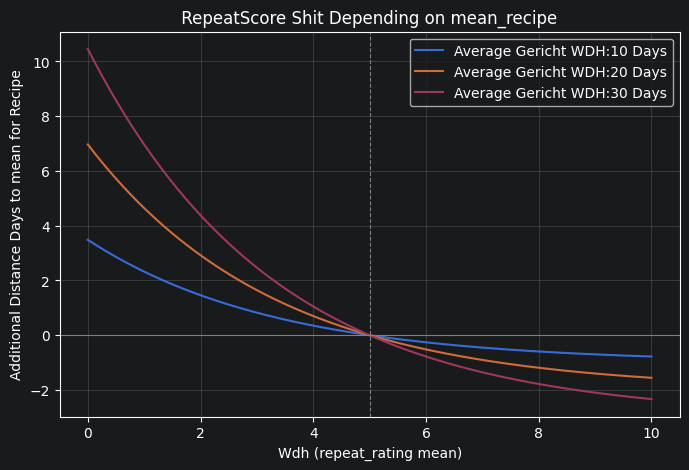

In [99]:
repeats = np.linspace(0, 10, 201)
mean_repeats=[10,20,30] #Wie Oft Gericht im Mean Gekocht Wurde

fig, ax = plt.subplots(figsize=(8, 5))
for mean_repeat in mean_repeats:
    y=repeat_weight(repeats,mean_repeat=mean_repeat)
    ax.plot(repeats, y,label=f"Average Gericht WDH:{mean_repeat} Days")

ax.axhline(0, color="gray", lw=0.8)
ax.axvline(MAX_SCORE/2, color="gray", lw=0.8, ls="--")
ax.set_xlabel("Wdh (repeat_rating mean)")
ax.set_ylabel("Additional Distance Days to mean for Recipe")
ax.set_title(f" RepeatScore Shit Depending on mean_recipe ")
ax.legend()
ax.grid(alpha=0.3)

### Calculating Ideal Distance for Recipe
## Split IN Two FIghting Factors
### I) Usage of repeat_score If its Low The Waiting Period should be longer if its High Only Small Improvments Should be made
### II) Correction Shift Calculated by Offset of periodcycle_app and mean_recipe, stdw_recipe

In [100]:
TARGET_LEVEL = 0.9       # beim Zielabstand T soll die Kurve 90 % vom Max erreichen
#Sigma contains around 68,27 %

def gauss(x, mu=0.0, var=1.0):
    x = np.asarray(x, dtype=float)
    return 1/(np.sqrt(var*2*np.pi)) * np.exp(-0.5 * ((x - mu)**2 )/var)

def gauss_cdf(x, mu=0.0, var=1.0):
    return 0.5 * (1 + erf((x - mu) / np.sqrt(2 * var)))

def truncated_gauss(x, mu=0.0, var=1.0, a=-np.inf, b=np.inf):
    x = np.asarray(x, dtype=float)
    Z = gauss_cdf(b, mu, var) - gauss_cdf(a, mu, var)
    y = gauss(x, mu, var) / Z
    return np.where((x >= a) & (x <= b), y, 0.0)

def improper_density_distribution(x, mu=0.0, var=1.0,amp=1):
    x = np.asarray(x, dtype=float)
    return amp * np.exp(-0.5 * ((x - mu)**2 )/var)


def ideal_distance_recipe(mean, M, repeat):
    """Zielabstand T = mean + w(repeat) * |M - mean|. Ohne mean (< 2 dates) gilt M."""
    mean = M if np.isnan(mean) else mean
    return mean + repeat_weight(repeat) * abs(M - mean)



Plot 1: mu = 5.0,  Var = 8.000
Plot 2: mu_days = 57.692, Var = 25
P(61 ≤ X ≤ 71) = 0.2696
P(53 ≤ X ≤ 63) = 0.6827
push to center 0.41, -3 days


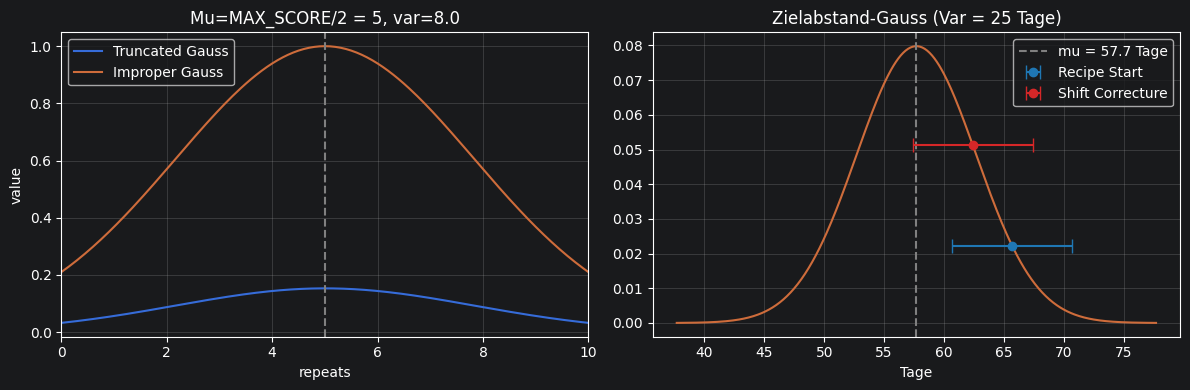

In [101]:
# Plot 1: Score-Gauss
var_score = 8.0 #points
# Plot 2: Zielabstand-Gauss (in Tagen)
 # ~57.7
var_days_app = min(30,COUNT_RECIPES_COOKED_ATLEAST_TWICE)                                   # Streuung in Tagen

x0, dx = periodcycle_app + 8, 5
a, b = x0 - dx, x0 + dx

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# 1) Gauss um MAX_SCORE/2, x von 0 bis MAX_SCORE
repeats = np.linspace(0, MAX_SCORE, 201)
ax1.plot(repeats, truncated_gauss(repeats, mu=MAX_SCORE / 2    , var=var_score,a=0,b=10),label=f"Truncated Gauss")
ax1.plot(repeats, improper_density_distribution(repeats, mu=MAX_SCORE / 2    , var=var_score),label=f"Improper Gauss ")
ax1.axvline(MAX_SCORE / 2, ls="--", color="gray")
ax1.set_title(f"Mu=MAX_SCORE/2 = {MAX_SCORE / 2:.0f}, var={var_score}")
ax1.set_xlabel("repeats")
ax1.set_ylabel("value")
ax1.set_xlim(0, MAX_SCORE)
ax1.legend(loc="upper left")
ax1.grid(True, alpha=0.3)

# 2) Gauss um mu (Tage), +/- 4 sigma
x_days = np.linspace(periodcycle_app - 20, periodcycle_app + 20, 401)
ax2.plot(x_days, gauss(x_days, mu=periodcycle_app, var=var_days_app), color="C1")
ax2.axvline(periodcycle_app, ls="--", color="gray", label=f"mu = {periodcycle_app:.1f} Tage")
ax2.errorbar(x0, gauss(x0, mu=periodcycle_app, var=var_days_app), xerr=dx, fmt='o', capsize=5, color='tab:blue', label="Recipe Start")
ax2.set_title(f"Zielabstand-Gauss (Var = {var_days_app:.0f} Tage)")
ax2.set_xlabel("Tage")

ax2.grid(True, alpha=0.3)



print(f"Plot 1: mu = {MAX_SCORE / 2},  Var = {var_score:.3f}")
print(f"Plot 2: mu_days = {periodcycle_app:.3f}, Var = {var_days_app}")

p_akt = gauss_cdf(b, periodcycle_app, var_days_app) - gauss_cdf(a, periodcycle_app, var_days_app)
p_best = gauss_cdf(periodcycle_app + dx, periodcycle_app, var_days_app) - gauss_cdf(periodcycle_app - dx, periodcycle_app, var_days_app)
print(f"P({a:.0f} ≤ X ≤ {b:.0f}) = {p_akt:.4f}")
print(f"P({periodcycle_app - dx:.0f} ≤ X ≤ {periodcycle_app + dx:.0f}) = {p_best:.4f}")

korrektur= (periodcycle_app - x0) * (p_best - p_akt)
print(f"push to center {p_best-p_akt:.2f}, {(periodcycle_app - x0) * (p_best - p_akt):.0f} days")

ax2.errorbar(x0 + korrektur, gauss(x0 + korrektur, mu=periodcycle_app, var=var_days_app), xerr=dx, fmt='o', capsize=5, color='tab:red', label="Shift Correcture")
plt.tight_layout()
ax2.legend()
plt.show()

### Shift Demonstraded How the Recipes should be distributed regarding the ideal spacing with periodcycle_app
### The Correction Shift get weighted by the repeat score here so if its in the middle more idealisation can happen at the boundry the other correction sould dominate

In [102]:
                  # Streuung Gericht variieren

def correction_days(recipe_mean,recipe_stdw,repat_score):
    p_akt = gauss_cdf(recipe_mean + recipe_stdw, periodcycle_app, var_days_app) - gauss_cdf(recipe_mean - recipe_stdw, periodcycle_app, var_days_app)
    p_best = gauss_cdf(periodcycle_app + recipe_stdw, periodcycle_app, var_days_app) - gauss_cdf(periodcycle_app - recipe_stdw, periodcycle_app, var_days_app)
    usage_score=improper_density_distribution(repat_score, mu=MAX_SCORE / 2    , var=var_score)
    korrektur= (periodcycle_app - recipe_mean) * (p_best - p_akt) * usage_score
    shift=repeat_weight(repat_score,mean_repeat=mean_repeat)
    return korrektur+shift

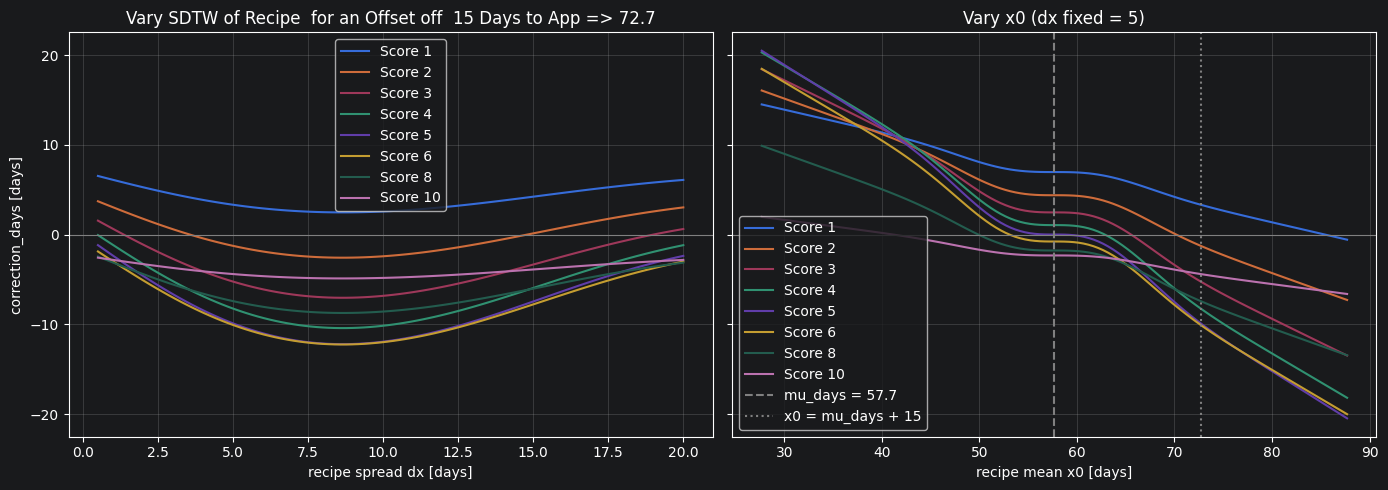

In [103]:
poss_scores = [1,2,3, 4,5, 6,8, 10]
x0_range = np.linspace(periodcycle_app - 30, periodcycle_app + 30, 121)
dx_range = np.linspace(0.5, 20, 100)

X0_FIX = periodcycle_app + 15   # x0 offset by 15 days, used while varying dx
DX_FIX = 5              # fixed dx, used while varying x0

fig, (ax_dx, ax_x0) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for pscore in poss_scores:
    # left: x0 fixed (offset 15), vary dx
    ax_dx.plot(dx_range, [correction_days(X0_FIX, dg, pscore) for dg in dx_range],
               label=f"Score {pscore}")
    # right: dx fixed, vary x0
    ax_x0.plot(x0_range, [correction_days(xg, DX_FIX, pscore) for xg in x0_range],
               label=f"Score {pscore}")

ax_dx.set_title(f"Vary SDTW of Recipe  for an Offset off  15 Days to App => {X0_FIX:.1f}")
ax_dx.set_xlabel("recipe spread dx [days]")
ax_dx.set_ylabel("correction_days [days]")

ax_x0.axvline(periodcycle_app, ls="--", color="gray", label=f"mu_days = {periodcycle_app:.1f}")
ax_x0.axvline(X0_FIX, ls=":", color="gray", label="x0 = mu_days + 15")
ax_x0.set_title(f"Vary x0 (dx fixed = {DX_FIX})")
ax_x0.set_xlabel("recipe mean x0 [days]")

for ax in (ax_dx, ax_x0):
    ax.axhline(0, color="gray", lw=0.8)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### Left Side Results in Constant repeat_weight Shift and only applicable for Shift to Center
### Alles Nähe 5 sollte störker einflusst werden

In [104]:
MIN_AMP = 0.1
MAX_AMP = 10

def get_amplification(last_cooked, ideal_spacing, tau=2.0):
    """Nähert sich MIN_AMP für last_cooked << ideal_spacing und MAX_AMP für last_cooked >> ideal_spacing.
    Bei last_cooked == ideal_spacing liegt genau die Mitte (5.05). tau = Breite des Übergangs."""
    t = np.tanh((last_cooked - ideal_spacing) / tau)
    return MIN_AMP + (MAX_AMP - MIN_AMP) * (t + 1) / 2

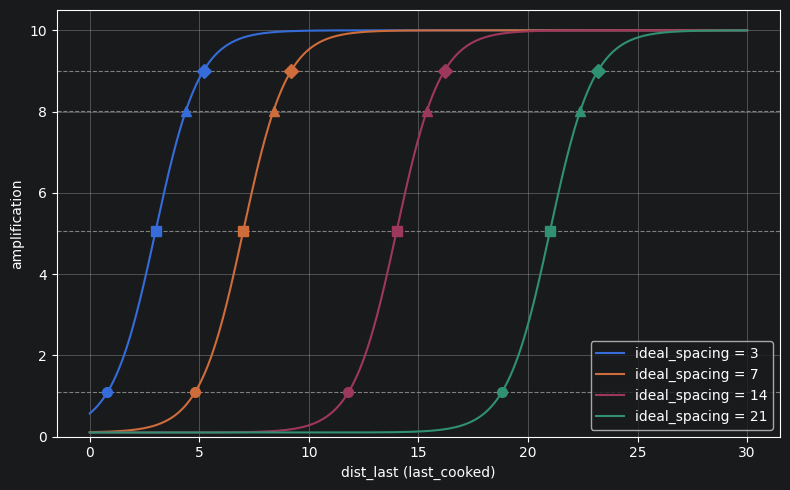

In [105]:
TAU = 2.0
dist_last = np.linspace(0, 30, 500)
IDEAL_SPACINGS = {3: "ideal_spacing = 3", 7: "ideal_spacing = 7",
                  14: "ideal_spacing = 14", 21: "ideal_spacing = 21"}
LEVELS = {0.1: "o", 0.5: "s", 0.8: "^", 0.9: "D"}   # Anteil zwischen MIN und MAX : Marker

fig, ax = plt.subplots(figsize=(8, 5))

for p in LEVELS:
    ax.axhline(MIN_AMP + p * (MAX_AMP - MIN_AMP), color="gray", ls="--", lw=0.8)

for s, label in IDEAL_SPACINGS.items():
    line, = ax.plot(dist_last, get_amplification(dist_last, s, TAU), label=label)
    for p, m in LEVELS.items():
        # Umkehrung: tanh((x - s)/tau) = 2p - 1  →  x = s + tau * arctanh(2p - 1)
        x = s + TAU * np.arctanh(2 * p - 1)
        if dist_last.min() <= x <= dist_last.max():
            y = MIN_AMP + p * (MAX_AMP - MIN_AMP)
            ax.plot(x, y, m, color=line.get_color(), ms=7)

ax.set_ylim(0, MAX_AMP + 0.5)
ax.set_xlabel("dist_last (last_cooked)")
ax.set_ylabel("amplification")
ax.legend()
ax.grid()
plt.tight_layout()
plt.show()

  ### Final Score Meassure Last Cooked - (Mean Cooked + Correction) to ampfilcation Factor